## 01 — Research question

### Exploring line movement

- **Owner:** Alex Gonzalez
- **Status:** Exploratory Analysis
- **Date:** October 24, 2026

Which bookmakers move their odds first, and which bookmakers follow?

### Scope

- **Date:** October 24, 2026
- **Games:** Games starting between 12:00 PM and 7:00 PM (the final scheduled game of the day)
- **Data Collection:** Odds are scraped every 15 minutes.

### Objective

Identify which bookmakers are the earliest to adjust their odds and which bookmakers tend to follow those movements.

The goal is to explore the timing and sequence of line movements across bookmakers.

## Data & Setup

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ANALYSIS_SRC = Path("src").resolve()
if not (ANALYSIS_SRC / "line_movement").is_dir():
    ANALYSIS_SRC = Path.cwd() / "notebooks/nba/line_movement_analysis/src"
if str(ANALYSIS_SRC) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_SRC))

from line_movement import (
    DEFAULT_FOLLOW_WINDOW,
    assign_move_waves,
    build_episodes,
    build_follows,
    build_market_groups,
    continuity_line_path,
    cross_book_groups,
    current_differences,
    detect_movements,
    filter_schedule,
    fixed_line_price_path,
    line_move_log,
    load_all_books,
    normalize_quotes,
    pairwise_stats,
    follower_rankings,
    plot_leader_follower_heatmap,
    plot_line_steps,
    plot_movement_timeline,
    plot_price_steps,
    save_daily_report,
    summarize_timeline,
    validate_quotes,
)
from line_movement.match import attach_market_keys
from line_movement.paths import analysis_root, repo_root

DATE = "2026-10-24"
ROOT = repo_root()
sns.set_theme(style="whitegrid")

## 02 — Load and validate data

In [2]:
raw = load_all_books(DATE, root=ROOT)
quotes = normalize_quotes(raw)
quotes, dropped = filter_schedule(quotes, date=DATE)
quality = validate_quotes(quotes)
quality.dropped_by_schedule = dropped
summary = (
    quotes.groupby("book", as_index=False)
    .agg(
        files=("source_file", "nunique"),
        rows=("player", "size"),
        players=("player_norm", "nunique"),
        props=("prop", "nunique"),
        first_snapshot=("snapshot_at", "min"),
        last_snapshot=("snapshot_at", "max"),
    )
)
summary

,book,files,rows,players,props,first_snapshot,last_snapshot
0,draftkings,22,50755,94,5,2026-10-24 12:02:46-07:00,2026-10-24 18:00:02-07:00
1,fanduel,27,42747,98,10,2026-10-24 12:02:45-07:00,2026-10-24 19:15:01-07:00
2,novig,27,84142,96,11,2026-10-24 12:02:45-07:00,2026-10-24 19:15:01-07:00
3,pinnacle,23,5378,82,3,2026-10-24 12:02:44-07:00,2026-10-24 18:15:00-07:00
4,prizepicks,27,111681,214,30,2026-10-24 12:02:45-07:00,2026-10-24 19:15:00-07:00
5,prophetx,27,95086,97,8,2026-10-24 12:02:45-07:00,2026-10-24 19:15:01-07:00
6,underdog,27,28308,133,14,2026-10-24 12:02:45-07:00,2026-10-24 19:15:00-07:00


Missing-field rates by book:

In [3]:
pd.DataFrame.from_dict(
    quality.missing_rates_by_book,
    orient="index",
).rename_axis("book")

,player,prop,side,line,american_price,event_key
book,,,,,,
draftkings,0.0,0.0,0.0,0.0,0.0,0.0
fanduel,0.0,0.0,0.0,0.0,0.0,0.0
novig,0.0,0.0,0.0,0.0,0.0,0.0
pinnacle,0.0,0.0,0.0,0.0,0.0,0.0
prizepicks,0.0,0.0,1.0,0.0,1.0,1.0
prophetx,0.0,0.0,0.0,0.0,0.0,0.0
underdog,0.0,0.0,0.0,0.0,0.0,1.0


## 03 — Match equivalent markets

In [4]:
quotes = attach_market_keys(quotes)
groups = build_market_groups(quotes)
cross = cross_book_groups(groups)
cross.sort_values("n_books", ascending=False).head(20)

,player_norm,event_key,prop,period,side,line,n_books,books,n_rows,matchable
408,kyle kuzma,milwaukee bucks__philadelphia 76ers,points,game,over,10.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",80,True
1470,zaccharie risacher,dallas mavericks__san antonio spurs,rebounds,game,over,4.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",28,True
438,jaylen brown,milwaukee bucks__philadelphia 76ers,assists,game,over,4.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",88,True
1462,zaccharie risacher,dallas mavericks__san antonio spurs,points,game,over,11.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",28,True
440,tyrese maxey,milwaukee bucks__philadelphia 76ers,assists,game,over,6.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",88,True
504,max christie,dallas mavericks__san antonio spurs,points,game,over,12.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",73,True
506,daniel gafford,dallas mavericks__san antonio spurs,points,game,over,8.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",85,True
510,devin vassell,dallas mavericks__san antonio spurs,points,game,over,11.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",93,True
512,dylan harper,dallas mavericks__san antonio spurs,points,game,over,17.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",92,True
514,stephon castle,dallas mavericks__san antonio spurs,points,game,over,17.5,5,"draftkings,fanduel,novig,pinnacle,prophetx",92,True


## 04 — Detect line and price changes

In [5]:
movements = detect_movements(quotes)
movements.head(20)

,book,player_norm,event_key,prop,period,side,series,prev_line,new_line,prev_american_price,new_american_price,change_type,line_up,line_down,price_shortened,price_lengthened,snapshot_at,prev_snapshot_at,lag_seconds,line_choice
0,novig,alperen sengun,atlanta hawks__houston rockets,points_rebounds,game,over,line,28.5,29.5,-127.0,-111.0,line,True,False,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
1,novig,alperen sengun,atlanta hawks__houston rockets,points_rebounds,game,under,line,28.5,29.5,-113.0,-135.0,line,True,False,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
2,novig,anthony davis,chicago bulls__washington wizards,rebounds_assists,game,over,line,13.5,14.5,-138.0,102.0,line,True,False,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
3,novig,anthony davis,chicago bulls__washington wizards,rebounds_assists,game,under,line,13.5,14.5,-104.0,-144.0,line,True,False,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
4,novig,bam adebayo,charlotte hornets__miami heat,points_rebounds_assists,game,over,line,30.5,29.5,-106.0,-115.0,line,False,True,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
5,novig,bam adebayo,charlotte hornets__miami heat,points_rebounds_assists,game,under,line,30.5,29.5,-125.0,-217.0,line,False,True,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
6,novig,daniel gafford,dallas mavericks__san antonio spurs,points,game,over,line,8.5,9.5,-104.0,115.0,line,True,False,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
7,novig,daniel gafford,dallas mavericks__san antonio spurs,points,game,under,line,8.5,9.5,-122.0,-413.0,line,True,False,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
8,novig,day ron sharpe,brooklyn nets__cleveland cavaliers,rebounds_assists,game,over,line,12.5,11.5,-100.0,-141.0,line,False,True,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main
9,novig,day ron sharpe,brooklyn nets__cleveland cavaliers,rebounds_assists,game,under,line,12.5,11.5,-144.0,-108.0,line,False,True,False,False,2026-10-24 12:15:00-07:00,2026-10-24 12:02:45-07:00,735.0,main


## 04b — Line and price step charts

Focus on one continuity market (player × event × prop × side).

1. **Line path** — time on X, line on Y, one color per book. Shows who moved the number, when, and **×** marks direction reversals.
2. **Price path at a fixed line** — American odds while books stayed on that number (price moves before a line change).

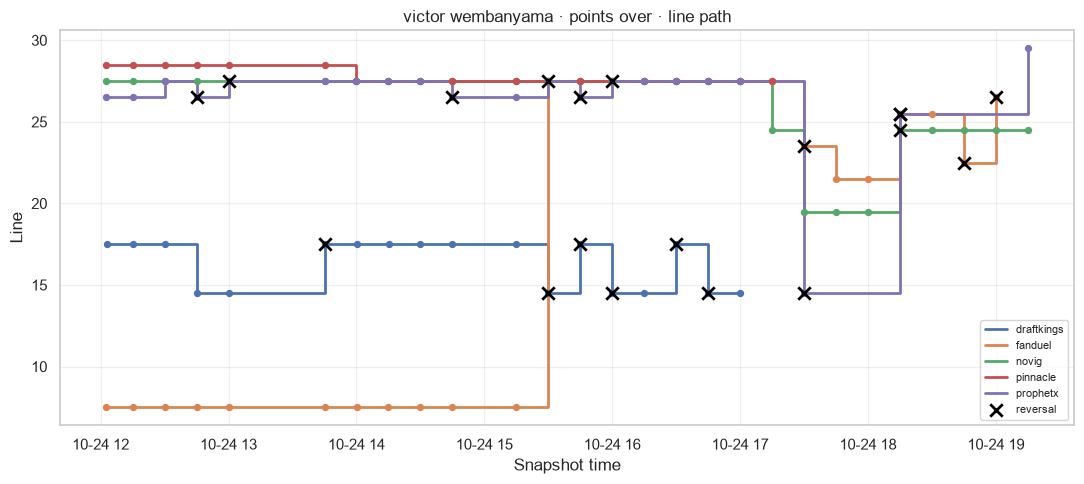

,book,snapshot_at,prev_line,new_line,direction,reversed,prev_snapshot_at,lag_seconds
0,draftkings,2026-10-24 12:45:02-07:00,17.5,14.5,down,False,2026-10-24 12:30:02-07:00,900.0
1,draftkings,2026-10-24 13:45:27-07:00,14.5,17.5,up,True,2026-10-24 13:00:02-07:00,2725.0
2,draftkings,2026-10-24 15:30:02-07:00,17.5,14.5,down,True,2026-10-24 15:15:02-07:00,900.0
3,draftkings,2026-10-24 15:45:02-07:00,14.5,17.5,up,True,2026-10-24 15:30:02-07:00,900.0
4,draftkings,2026-10-24 16:00:02-07:00,17.5,14.5,down,True,2026-10-24 15:45:02-07:00,900.0
5,draftkings,2026-10-24 16:30:02-07:00,14.5,17.5,up,True,2026-10-24 16:15:02-07:00,900.0
6,draftkings,2026-10-24 16:45:02-07:00,17.5,14.5,down,True,2026-10-24 16:30:02-07:00,900.0
7,fanduel,2026-10-24 15:30:02-07:00,7.5,27.5,up,False,2026-10-24 15:15:02-07:00,900.0
8,fanduel,2026-10-24 17:30:02-07:00,27.5,23.5,down,True,2026-10-24 17:15:02-07:00,900.0
9,fanduel,2026-10-24 17:45:02-07:00,23.5,21.5,down,False,2026-10-24 17:30:02-07:00,900.0


In [6]:
FOCUS = {
    "player_norm": "victor wembanyama",
    "event_key": "dallas mavericks__san antonio spurs",
    "prop": "points",
    "period": "game",
    "side": "over",
}

line_path = continuity_line_path(quotes, **FOCUS)
move_log = line_move_log(movements, **FOCUS)

fig, ax = plt.subplots(figsize=(11, 5))
plot_line_steps(
    line_path,
    ax=ax,
    title=(
        f"{FOCUS['player_norm']} · {FOCUS['prop']} {FOCUS['side']} · line path"
    ),
    reversals=move_log,
)
plt.tight_layout()
plt.show()

move_log

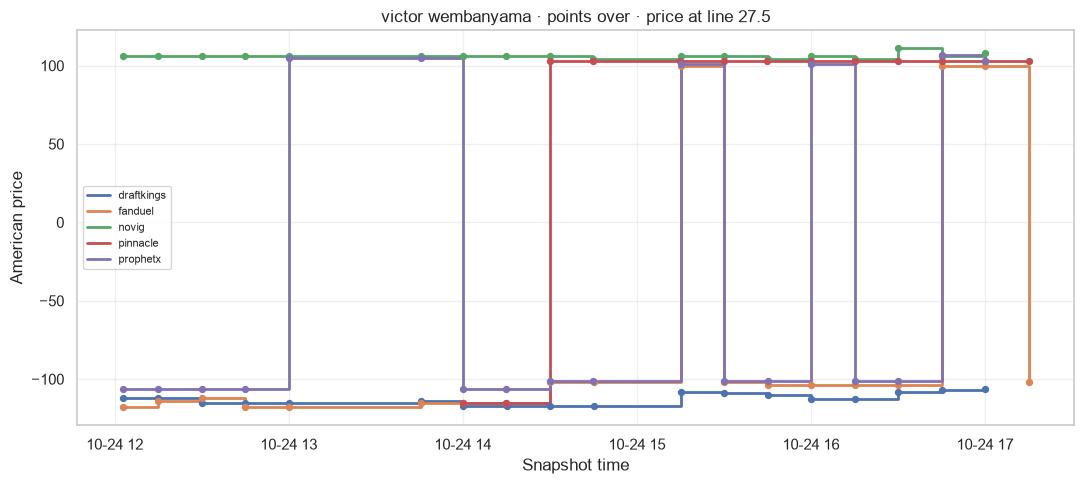

,snapshot_at,book,line,american_price
18,2026-10-24 12:02:45-07:00,fanduel,27.5,-118.0
37,2026-10-24 12:02:45-07:00,novig,27.5,106.0
68,2026-10-24 12:02:45-07:00,prophetx,27.5,-106.0
0,2026-10-24 12:02:46-07:00,draftkings,27.5,-112.0
38,2026-10-24 12:15:00-07:00,novig,27.5,106.0
69,2026-10-24 12:15:00-07:00,prophetx,27.5,-106.0
19,2026-10-24 12:15:01-07:00,fanduel,27.5,-114.0
1,2026-10-24 12:15:02-07:00,draftkings,27.5,-112.0
20,2026-10-24 12:30:01-07:00,fanduel,27.5,-112.0
39,2026-10-24 12:30:01-07:00,novig,27.5,106.0


In [7]:
# Fixed line with the most books quoting a price (odds churn before the number moves).
market = quotes
for key, value in FOCUS.items():
    market = market.loc[market[key].eq(value)]
line_coverage = (
    market.loc[market["american_price"].notna() & market["line"].between(15, 45)]
    .groupby("line")["book"]
    .nunique()
    .sort_values(ascending=False)
)
FOCUS_LINE = float(line_coverage.index[0])
price_path = fixed_line_price_path(quotes, line=FOCUS_LINE, **FOCUS)

fig, ax = plt.subplots(figsize=(11, 5))
plot_price_steps(
    price_path,
    ax=ax,
    title=(
        f"{FOCUS['player_norm']} · {FOCUS['prop']} {FOCUS['side']} "
        f"· price at line {FOCUS_LINE:g}"
    ),
)
plt.tight_layout()
plt.show()

(
    price_path.sort_values(["snapshot_at", "book"])
    .loc[:, ["snapshot_at", "book", "line", "american_price"]]
    .head(30)
)

### Movement timeline

One row per book. Dots mark each line change; color is direction (`up` / `down`). Shaded bands are **waves** (moves within 5 minutes). The title says whether books clustered, moved in waves, or stayed separate.

Waves — 6 multi-book clusters, 12 solo
moves=27  waves=18  multi-book=6  solo=12


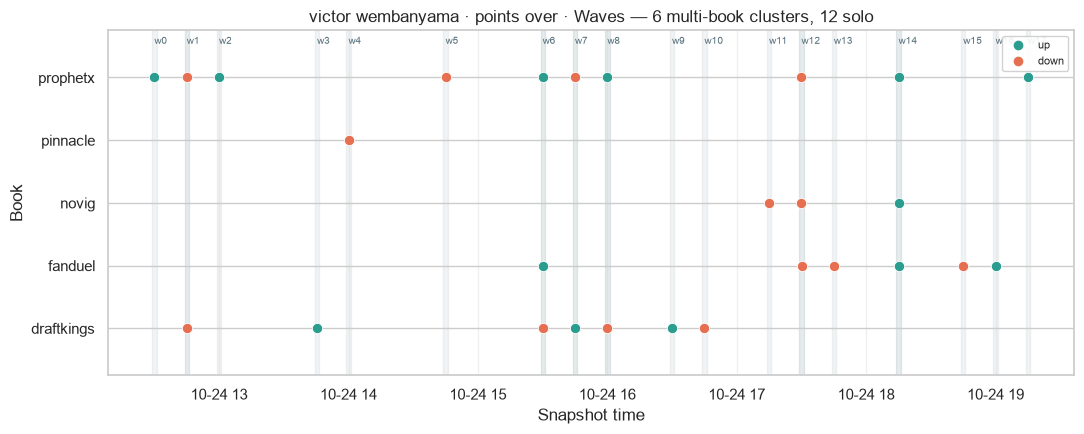

,wave_id,start,end,books,n_books,directions
0,0,2026-10-24 12:30:01-07:00,2026-10-24 12:30:01-07:00,prophetx,1,up
1,1,2026-10-24 12:45:01-07:00,2026-10-24 12:45:02-07:00,"draftkings,prophetx",2,down
2,2,2026-10-24 13:00:00-07:00,2026-10-24 13:00:00-07:00,prophetx,1,up
3,3,2026-10-24 13:45:27-07:00,2026-10-24 13:45:27-07:00,draftkings,1,up
4,4,2026-10-24 14:00:00-07:00,2026-10-24 14:00:00-07:00,pinnacle,1,down
5,5,2026-10-24 14:45:01-07:00,2026-10-24 14:45:01-07:00,prophetx,1,down
6,6,2026-10-24 15:30:01-07:00,2026-10-24 15:30:02-07:00,"draftkings,fanduel,prophetx",3,"down,up"
7,7,2026-10-24 15:45:01-07:00,2026-10-24 15:45:02-07:00,"draftkings,prophetx",2,"down,up"
8,8,2026-10-24 16:00:01-07:00,2026-10-24 16:00:02-07:00,"draftkings,prophetx",2,"down,up"
9,9,2026-10-24 16:30:02-07:00,2026-10-24 16:30:02-07:00,draftkings,1,up


In [8]:
timeline = assign_move_waves(move_log)
summary = summarize_timeline(timeline)
print(summary["label"])
print(
    f"moves={summary['n_moves']}  waves={summary['n_waves']}  "
    f"multi-book={summary['multi_book_waves']}  solo={summary['solo_waves']}"
)

fig, ax = plt.subplots(figsize=(11, 4.5))
plot_movement_timeline(
    timeline,
    ax=ax,
    title=(
        f"{FOCUS['player_norm']} · {FOCUS['prop']} {FOCUS['side']} · "
        f"{summary['label']}"
    ),
)
plt.tight_layout()
plt.show()

(
    timeline.groupby("wave_id", as_index=False)
    .agg(
        start=("snapshot_at", "min"),
        end=("snapshot_at", "max"),
        books=("book", lambda s: ",".join(sorted(set(s)))),
        n_books=("book", "nunique"),
        directions=("direction", lambda s: ",".join(sorted(set(s.dropna().astype(str))))),
    )
    .sort_values("start")
)

### Current differences

Latest quote per book on the FOCUS market vs the **consensus line** (median across books).

- `gap_from_consensus` — how far this book’s line sits from peers
- `gap_persisted_sec` — how long that disagreement has lasted
- `quote_age_sec` — freshness vs the latest snapshot clock
- `price_gap_from_peers` — American price vs median price of books on the consensus line

In [9]:
diffs = current_differences(quotes, **FOCUS)

display(
    diffs.loc[
        :,
        [
            "book",
            "current_line",
            "american_price",
            "consensus_line",
            "gap_from_consensus",
            "price_gap_from_peers",
            "gap_persisted_sec",
            "quote_age_sec",
            "differs",
        ],
    ].assign(
        gap_persisted_min=lambda d: (d["gap_persisted_sec"] / 60).round(1),
        quote_age_min=lambda d: (d["quote_age_sec"] / 60).round(1),
    )
)

print(
    f"as_of={diffs['as_of'].iloc[0] if len(diffs) else None}  "
    f"books_differing={int(diffs['differs'].sum()) if len(diffs) else 0}/"
    f"{len(diffs)}"
)
diffs.loc[diffs["differs"]]

,book,current_line,american_price,consensus_line,gap_from_consensus,price_gap_from_peers,gap_persisted_sec,quote_age_sec,differs,gap_persisted_min,quote_age_min
0,pinnacle,27.5,103.0,26.5,1.0,231.0,25937.0,7201.0,True,432.3,120.0
1,novig,24.5,-251.0,26.5,-2.0,-123.0,25936.0,0.0,True,432.3,0.0
2,draftkings,14.5,-1800.0,26.5,-12.0,-1672.0,25935.0,8099.0,True,432.2,135.0
3,prophetx,29.5,-118.0,26.5,3.0,10.0,11700.0,0.0,True,195.0,0.0
4,fanduel,26.5,-128.0,26.5,0.0,0.0,0.0,899.0,False,0.0,15.0


as_of=2026-10-24 19:15:01-07:00  books_differing=4/5


,book,current_line,american_price,consensus_line,gap_from_consensus,price_gap_from_peers,gap_persisted_sec,quote_age_sec,differs,as_of,snapshot_at
0,pinnacle,27.5,103.0,26.5,1.0,231.0,25937.0,7201.0,True,2026-10-24 19:15:01-07:00,2026-10-24 17:15:00-07:00
1,novig,24.5,-251.0,26.5,-2.0,-123.0,25936.0,0.0,True,2026-10-24 19:15:01-07:00,2026-10-24 19:15:01-07:00
2,draftkings,14.5,-1800.0,26.5,-12.0,-1672.0,25935.0,8099.0,True,2026-10-24 19:15:01-07:00,2026-10-24 17:00:02-07:00
3,prophetx,29.5,-118.0,26.5,3.0,10.0,11700.0,0.0,True,2026-10-24 19:15:01-07:00,2026-10-24 19:15:01-07:00


## 05 — Analyze leader/follower relationships

**Heatmap:** rows = first mover, columns = responding book, color = median delay (seconds within the 30‑minute window).

Darker / higher values mean the follower typically reacts later. Books that show up often as columns (and rank high in the follower table) repeatedly move after others.

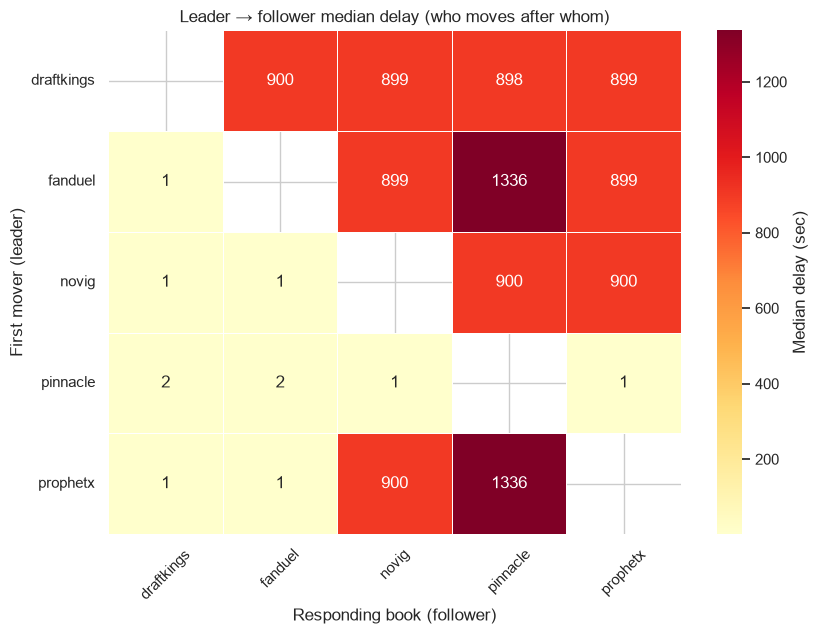

Books that most often respond after another book leads:


,follower_book,follow_count,leaders_followed,median_lag_sec
0,prophetx,7541,4,899.0
1,fanduel,7079,4,1.5
2,novig,3949,4,899.0
3,draftkings,880,4,1.0
4,pinnacle,272,4,1118.0


,leader_book,follower_book,lead_count,follow_count_windowed,follow_rate_windowed,median_lag_windowed_sec,mean_lag_windowed_sec,median_lag_uncapped_sec
11,novig,prophetx,11932,5293,0.443597,900.0,970.201398,900.0
9,novig,fanduel,11932,5155,0.432032,1.0,365.459554,1.0
5,fanduel,novig,8030,2139,0.266376,899.0,1151.776531,899.0
7,fanduel,prophetx,8030,1860,0.231631,899.0,1173.257527,899.0
17,prophetx,fanduel,4601,1668,0.362530,1.0,395.190048,1.0
18,prophetx,novig,4601,1386,0.301239,900.0,1134.233045,900.0
8,novig,draftkings,11932,637,0.053386,1.0,199.579278,1.0
1,draftkings,novig,1967,272,0.138282,899.0,1127.551471,899.0
3,draftkings,prophetx,1967,254,0.129131,899.0,1114.905512,899.0
10,novig,pinnacle,11932,202,0.016929,900.0,1291.574257,900.0


In [10]:
episodes = build_episodes(movements, window=DEFAULT_FOLLOW_WINDOW)
follows = build_follows(movements, episodes, window=DEFAULT_FOLLOW_WINDOW)
pairwise = pairwise_stats(follows, episodes)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
plot_leader_follower_heatmap(pairwise, ax=ax)
plt.tight_layout()
plt.show()

print("Books that most often respond after another book leads:")
display(follower_rankings(pairwise))
display(pairwise.sort_values("follow_count_windowed", ascending=False).head(20))

## 06 — Daily report

Scrape resolution is approximately 15 minutes; first-observed movement does not prove true market leadership.

In [11]:
out = save_daily_report(
    date=DATE,
    quotes=quotes,
    groups=groups,
    movements=movements,
    episodes=episodes,
    follows=follows,
    pairwise=pairwise,
    quality=quality,
    analysis_root=analysis_root(),
)
print(out)

/Users/alexgonzalez/Documents/nba_quant/notebooks/nba/line_movement_analysis/reports/2026-10-24
